TRAVAIL FAIT PAR: meryem oujedid et fatima ezzahra naciri

### Étape 1 : Connexion au Google Drive
Exécutez cette cellule pour monter votre Google Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Étape 2 : Chargement des données
Nous allons charger le fichier Excel `dataset1.xls` à l'aide de pandas et afficher les premières lignes.

In [ ]:
import pandas as pd

# Nouveau chemin d'accès demandé
file_path = '/content/drive/MyDrive/fatima-ezzahra naciri _fin3_TP2/dataset-TP2.xls'

try:
    # On tente d'abord de lire avec un séparateur tabulation
    df = pd.read_csv(file_path, sep='\t')
except Exception as e:
    print(f"Échec avec tabulation: {e}. Essai avec virgule...")
    df = pd.read_csv(file_path, sep=',')

# Suppression des espaces éventuels dans les noms de colonnes
df.columns = df.columns.str.strip()

# Affichage des premières lignes pour confirmation
display(df.head(10))

,Facility,Date of,Expiration,Amount,Amount.1,Amount.2
0,NaN,Arrangement,Date 4/,Agreed,Drawn,Outstanding
1,NaN,NaN,NaN,NaN,NaN,NaN
2,Flexible Credit Line,"Apr 02, 2025","Apr 01, 2027","3,450,000",0,0
3,Resilience and Sustainability Facility,"Sep 28, 2023","Apr 02, 2025","1,000,000","937,5","937,5"
4,Flexible Credit Line,"Apr 03, 2023","Apr 02, 2025","3,726,200",0,0
5,Precautionary and Liquidity Line,"Dec 17, 2018","Apr 07, 2020","2,150,800","2,150,800",0
6,Precautionary and Liquidity Line,"Jul 22, 2016","Jul 21, 2018","2,504,000",0,0
7,Precautionary and Liquidity Line,"Jul 28, 2014","Jul 21, 2016","3,235,100",0,0
8,Precautionary and Liquidity Line,"Aug 03, 2012","Jul 27, 2014","4,117,400",0,0
9,Standby Arrangement,"Jan 31, 1992","Mar 31, 1993","91,98","18,396",0


In [ ]:
import sqlite3
import pandas as pd

# 1. Connexion / Création de la base de données SQLite
conn = sqlite3.connect('tp_database.db')

# On s'assure de nettoyer les colonnes pour enlever d'éventuels espaces
df.columns = df.columns.str.strip()

# 2. Exportation du DataFrame pandas vers la table 'dataset' dans SQLite
df.to_sql('dataset', conn, if_exists='replace', index=False)

print("Base de données 'tp_database.db' créée avec succès et table 'dataset' insérée !")

Base de données 'tp_database.db' créée avec succès et table 'dataset' insérée !


In [ ]:
# Requête de vérification du nombre total de lignes insérées
query_count = "SELECT COUNT(*) AS total_lignes FROM dataset"
res_count = pd.read_sql_query(query_count, conn)
display(res_count)

# Requête de calcul des statistiques globales agrégées par type de facilité
query_stats = """
SELECT
    Facility,
    COUNT(*) as total_accords,
    SUM(CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL)) as total_amount_agreed,
    AVG(CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL)) as moyenne_amount_agreed
FROM dataset
WHERE Facility IS NOT NULL
  AND Facility != 'Facility'
  AND Amount IS NOT NULL
  AND Amount != 'Agreed'
GROUP BY Facility
"""
res_stats = pd.read_sql_query(query_stats, conn)
display(res_stats)

,total_lignes
0,26


,Facility,total_accords,total_amount_agreed,moyenne_amount_agreed
0,Total,1,23475780.0,2.347578e+07
1,Extended Fund Facility,2,82515.0,4.125750e+04
2,Flexible Credit Line,2,7176200.0,3.588100e+06
3,Precautionary and Liquidity Line,4,12007300.0,3.001825e+06
4,Resilience and Sustainability Facility,1,1000000.0,1.000000e+06
5,Standby Arrangement,14,38615.0,2.758214e+03


In [ ]:
import sqlite3
import pandas as pd

# Connexion à la base de données SQLite
conn = sqlite3.connect('tp_database.db')

# S'assurer d'exporter la table 'dataset' à partir du DataFrame chargé
df.columns = df.columns.str.strip()
df.to_sql('dataset', conn, if_exists='replace', index=False)
print("Base de données reconnectée et table 'dataset' restaurée avec succès !")

Base de données reconnectée et table 'dataset' restaurée avec succès !


**Exercice 1 :** Afficher les 5 premières lignes de la table `dataset` pour inspecter la structure globale.

In [ ]:
query_1 = "SELECT * FROM dataset LIMIT 5"
pd.read_sql_query(query_1, conn)

,Facility,Date of,Expiration,Amount,Amount.1,Amount.2
0,None,Arrangement,Date 4/,Agreed,Drawn,Outstanding
1,None,None,None,None,None,None
2,Flexible Credit Line,"Apr 02, 2025","Apr 01, 2027","3,450,000",0,0
3,Resilience and Sustainability Facility,"Sep 28, 2023","Apr 02, 2025","1,000,000","937,5","937,5"
4,Flexible Credit Line,"Apr 03, 2023","Apr 02, 2025","3,726,200",0,0


**Exercice 2 :** Compter le nombre total d'enregistrements (lignes) dans la table (excluant l'en-tête technique si présent).

In [ ]:
query_2 = """
SELECT COUNT(*) AS total_enregistrements
FROM dataset
WHERE Facility IS NOT NULL AND Facility != 'Facility'
"""
pd.read_sql_query(query_2, conn)

,total_enregistrements
0,24


**Exercice 3 :** Lister les types de facilités (`Facility`) uniques présents dans la base de données.

In [ ]:
query_3 = """
SELECT DISTINCT Facility
FROM dataset
WHERE Facility IS NOT NULL AND Facility != 'Facility' AND Facility != 'Total'
"""
pd.read_sql_query(query_3, conn)

,Facility
0,Flexible Credit Line
1,Resilience and Sustainability Facility
2,Precautionary and Liquidity Line
3,Standby Arrangement
4,Extended Fund Facility
5,Total


**Exercice 4 :** Compter le nombre de fois que chaque facilité a été accordée.

In [ ]:
query_4 = """
SELECT Facility, COUNT(*) AS nombre_accords
FROM dataset
WHERE Facility IS NOT NULL AND Facility != 'Facility' AND Facility != 'Total'
GROUP BY Facility
ORDER BY nombre_accords DESC
"""
pd.read_sql_query(query_4, conn)

,Facility,nombre_accords
0,Standby Arrangement,14
1,Precautionary and Liquidity Line,4
2,Flexible Credit Line,2
3,Extended Fund Facility,2
4,Resilience and Sustainability Facility,1
5,Total,1


**Exercice 5 :** Trouver le montant maximum accordé parmi tous les enregistrements (après conversion du champ `Amount`).

In [ ]:
query_5 = """
SELECT MAX(CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL)) AS montant_maximal
FROM dataset
WHERE Facility != 'Total' AND Amount IS NOT NULL AND Amount != 'Agreed'
"""
pd.read_sql_query(query_5, conn)

,montant_maximal
0,23475780.0


**Exercice 6 :** Calculer la somme totale de tous les montants approuvés par le FMI.

In [ ]:
query_6 = """
SELECT SUM(CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL)) AS total_montants
FROM dataset
WHERE Facility != 'Total' AND Amount IS NOT NULL AND Amount != 'Agreed'
"""
pd.read_sql_query(query_6, conn)

,total_montants
0,43780410.0


**Exercice 7 :** Calculer la moyenne des montants accordés.

In [ ]:
query_7 = """
SELECT AVG(CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL)) AS moyenne_montants
FROM dataset
WHERE Facility != 'Total' AND Amount IS NOT NULL AND Amount != 'Agreed'
"""
pd.read_sql_query(query_7, conn)

,moyenne_montants
0,1824183.75


**Exercice 8 :** Trouver toutes les lignes dont le montant accordé est supérieur à 1 000 000 (en valeur nettoyée).

In [ ]:
query_8 = """
SELECT *
FROM dataset
WHERE CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL) > 1000000
  AND Facility != 'Total' AND Facility != 'Facility'
"""
pd.read_sql_query(query_8, conn)

,Facility,Date of,Expiration,Amount,Amount.1,Amount.2
0,Flexible Credit Line,"Apr 02, 2025","Apr 01, 2027","3,450,000",0,0
1,Flexible Credit Line,"Apr 03, 2023","Apr 02, 2025","3,726,200",0,0
2,Precautionary and Liquidity Line,"Dec 17, 2018","Apr 07, 2020","2,150,800","2,150,800",0
3,Precautionary and Liquidity Line,"Jul 22, 2016","Jul 21, 2018","2,504,000",0,0
4,Precautionary and Liquidity Line,"Jul 28, 2014","Jul 21, 2016","3,235,100",0,0
5,Precautionary and Liquidity Line,"Aug 03, 2012","Jul 27, 2014","4,117,400",0,0
6,Total,None,None,"23,475,780","4,547,696","937,5"


**Exercice 9 :** Classer les accords par ordre chronologique de la date d'accord (`Date of Arrangement`).

In [ ]:
query_9 = """
SELECT *
FROM dataset
WHERE [Date of] IS NOT NULL AND [Date of] != 'Arrangement'
ORDER BY [Date of] ASC
"""
pd.read_sql_query(query_9, conn)

,Facility,Date of,Expiration,Amount,Amount.1,Amount.2
0,Flexible Credit Line,"Apr 02, 2025","Apr 01, 2027","3,450,000",0,0
1,Flexible Credit Line,"Apr 03, 2023","Apr 02, 2025","3,726,200",0,0
2,Standby Arrangement,"Apr 26, 1982","Apr 25, 1983","281,25","281,25",0
3,Precautionary and Liquidity Line,"Aug 03, 2012","Jul 27, 2014","4,117,400",0,0
4,Standby Arrangement,"Aug 30, 1988","Dec 31, 1989",210,210,0
5,Standby Arrangement,"Dec 15, 1969","Dec 14, 1970",25,10,0
6,Standby Arrangement,"Dec 16, 1986","Apr 30, 1988",230,230,0
7,Precautionary and Liquidity Line,"Dec 17, 2018","Apr 07, 2020","2,150,800","2,150,800",0
8,Standby Arrangement,"Jan 31, 1992","Mar 31, 1993","91,98","18,396",0
9,Standby Arrangement,"Jul 20, 1990","Mar 31, 1991",100,48,0


**Exercice 10 :** Trouver le nombre d'accords qui n'ont pas encore expiré (comparés avec une date de référence, par exemple l'année 2026).

In [ ]:
query_10 = """
SELECT COUNT(*) AS accords_futurs
FROM dataset
WHERE Expiration LIKE '%2026%' OR Expiration LIKE '%2027%'
"""
pd.read_sql_query(query_10, conn)

,accords_futurs
0,1


**Exercice 11 :** Regrouper et obtenir la somme des montants par type de facilité, triée de manière décroissante.

In [ ]:
query_11 = """
SELECT Facility, SUM(CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL)) AS total_fac
FROM dataset
WHERE Facility IS NOT NULL AND Facility != 'Facility' AND Facility != 'Total'
GROUP BY Facility
ORDER BY total_fac DESC
"""
pd.read_sql_query(query_11, conn)

,Facility,total_fac
0,Total,23475780.0
1,Precautionary and Liquidity Line,12007300.0
2,Flexible Credit Line,7176200.0
3,Resilience and Sustainability Facility,1000000.0
4,Extended Fund Facility,82515.0
5,Standby Arrangement,38615.0


**Exercice 12 :** Trouver la facilité qui a le plus petit montant moyen accordé.

In [ ]:
query_12 = """
SELECT Facility, AVG(CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL)) AS moyenne_fac
FROM dataset
WHERE Facility IS NOT NULL AND Facility != 'Facility' AND Facility != 'Total'
GROUP BY Facility
ORDER BY moyenne_fac ASC
LIMIT 1
"""
pd.read_sql_query(query_12, conn)

,Facility,moyenne_fac
0,Standby Arrangement,2758.214286


**Exercice 13 :** Obtenir les accords dont le montant est compris entre 10 000 et 500 000.

In [ ]:
query_13 = """
SELECT *
FROM dataset
WHERE CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL) BETWEEN 10000 AND 500000
  AND Facility != 'Total' AND Facility != 'Facility'
"""
pd.read_sql_query(query_13, conn)

,Facility,Date of,Expiration,Amount,Amount.1,Amount.2
0,Standby Arrangement,"Apr 26, 1982","Apr 25, 1983","281,25","281,25",0
1,Extended Fund Facility,"Mar 09, 1981","Apr 25, 1982","817,05","136,5",0


**Exercice 14 :** Identifier les types d'accords qui ont un montant cumulé supérieur à 5 000 000.

In [ ]:
query_14 = """
SELECT Facility, SUM(CAST(REPLACE(REPLACE(Amount, ',', ''), ' ', '') AS REAL)) AS total_fac
FROM dataset
WHERE Facility IS NOT NULL AND Facility != 'Facility' AND Facility != 'Total'
GROUP BY Facility
HAVING total_fac > 5000000
"""
pd.read_sql_query(query_14, conn)

,Facility,total_fac
0,Total,23475780.0
1,Flexible Credit Line,7176200.0
2,Precautionary and Liquidity Line,12007300.0


**Exercice 15 :** Compter le nombre de types de facilités distinctes ayant reçu au moins un accord.

In [ ]:
query_15 = """
SELECT COUNT(DISTINCT Facility) AS nb_facilities_actives
FROM dataset
WHERE Facility IS NOT NULL AND Facility != 'Facility' AND Facility != 'Total' AND Amount IS NOT NULL
"""
pd.read_sql_query(query_15, conn)

,nb_facilities_actives
0,6


### Étape 4 : Visualisation Graphique des Résultats SQL

Visualisons maintenant graphiquement les montants cumulés pour chaque type de facilité à l'aide de matplotlib et seaborn.

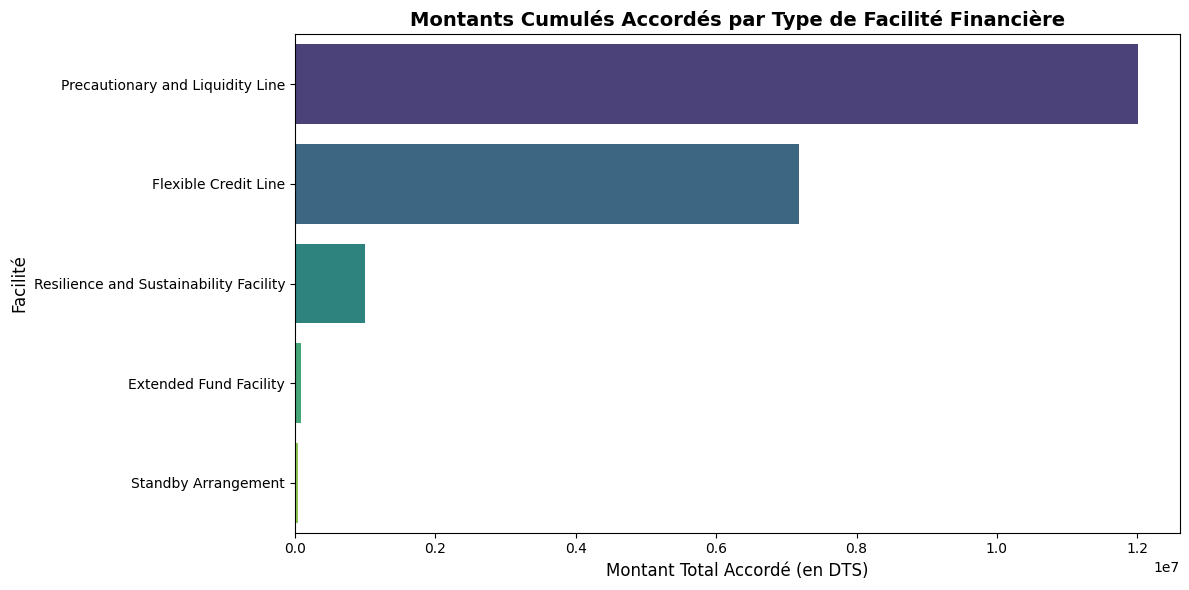

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrage de la ligne de total général pour la visualisation
data_plot = res_stats[~res_stats['Facility'].str.lower().str.contains('total', na=False)]

plt.figure(figsize=(12, 6))
sns.barplot(
    x='total_amount_agreed',
    y='Facility',
    data=data_plot.sort_values(by='total_amount_agreed', ascending=False),
    hue='Facility',
    palette='viridis',
    legend=False
)

plt.title('Montants Cumulés Accordés par Type de Facilité Financière', fontsize=14, fontweight='bold')
plt.xlabel('Montant Total Accordé (en DTS)', fontsize=12)
plt.ylabel('Facilité', fontsize=12)
plt.tight_layout()
plt.show()

### Étape 5 : Clôture de la Connexion et Documentation

Il est primordial de libérer les ressources système et de fermer la connexion à la base de données une fois les analyses finies.

In [ ]:
# Fermeture de la connexion SQLite
try:
    conn.close()
    print("La connexion à la base de données SQLite a été fermée proprement.")
except Exception as e:
    print(f"Erreur lors de la fermeture de la connexion : {e}")

La connexion à la base de données SQLite a été fermée proprement.
